**Цель работы:** изучение алгоритмов регрессии на практике: простая и полиномиальная линейная регрессия, оценка качества моделей метриками (MAE, MSE, RMSE, MAPE, R2), диагностика остатков, а также решение задачи регрессии различными методами (линейная регрессия, k-ближайших соседей, дерево решений).

**Вариант №5**

Работа состоит из трёх частей:
- **Часть 1** — простая линейная регрессия (набор `regression.xlsx`, лист `var5`);
- **Часть 2** — полиномиальная регрессия;
- **Часть 3** — решение задачи регрессии различными методами (набор `salary.csv`).

# Часть 1. Простая линейная регрессия

## 1. Описание данных и загрузка

Набор `regression.xlsx` содержит листы `var1`–`var10` (по одному на вариант). Для варианта №5 используется лист **`var5`**.

Столбцы:
- `x1` — первый признак;
- `x2` — второй признак;
- `y` — целевая переменная.

In [2]:
# Импорт библиотек и чтение файла с помощью pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics

%matplotlib inline
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42  # фиксируем сид для воспроизводимости результатов

# Лист варианта №5
df = pd.read_excel('regression.xlsx', sheet_name='var5')
print('Размер набора данных:', df.shape)
df.head()

Размер набора данных: (1000, 3)


,x1,x2,y
0,1.227510,1.757661,0.933986
1,1.289365,-0.811436,-0.590249
2,1.772339,-1.089542,-1.067998
3,1.845956,1.861446,1.975436
4,0.422230,-0.416797,-0.264838


### 1.1 Описательные статистики

In [3]:
df.describe()

,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,-0.000030,0.000039,0.131472
std,1.155282,1.155189,0.956987
min,-1.996262,-1.997311,-2.203398
25%,-1.000689,-0.998199,-0.613391
50%,0.000505,0.000224,0.112751
75%,0.999931,1.000881,0.843450
max,1.996164,1.997478,2.877632


### 1.2 Парные коэффициенты корреляции Пирсона

Коэффициенты корреляции Пирсона с целевой переменной y:
x1    0.050406
x2    0.843833
y     1.000000
Name: y, dtype: float64


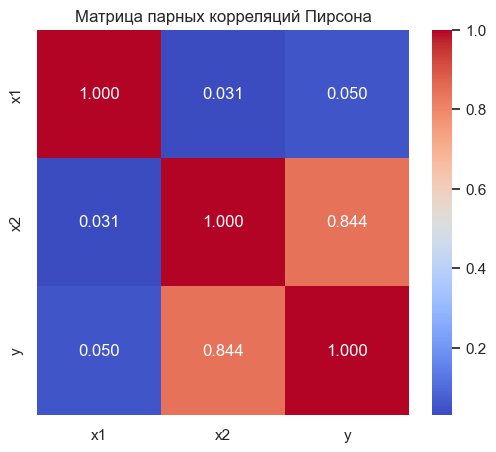

In [4]:
corr = df.corr(method='pearson')
print('Коэффициенты корреляции Пирсона с целевой переменной y:')
print(corr['y'])

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f')
plt.title('Матрица парных корреляций Пирсона')
plt.show()

**Предварительное заключение о связи.**

На тепловой карте коэффициентов корреляции самая интенсивная окраска в строке `y` соответствует `x2` (0.844), а ячейка `x1`–`y` близка к нейтральной (0.050). Между `x2` и `y` наблюдается **сильная положительная линейная связь**, между `x1` и `y` линейная связь **практически отсутствует**. Следовательно, для простой линейной регрессии `x2` будет хорошим предиктором, а `x1` — плохим. При этом слабая корреляция `x1` не исключает нелинейной зависимости (это проверим в Части&nbsp;2).

## 2. Простая (парная) линейная регрессия

Обучим две модели: `y` от `x1` и `y` от `x2`. Выборку делим на обучающую и валидационную в соотношении 75/25.

In [5]:
def simple_regression(feature):
    # x – признак, y – целевой признак
    x = df[[feature]]
    y = df['y']
    # Разделение выборки на обучающую и валидационную
    x_train, x_valid, y_train, y_valid = train_test_split(
        x, y, test_size=0.25, random_state=RANDOM_STATE)

    model = LinearRegression()
    model.fit(x_train, y_train)       # обучение модели
    y_pred = model.predict(x_valid)   # предсказание на валидации

    return {
        'feature': feature,
        'model': model,
        'x_train': x_train, 'x_valid': x_valid,
        'y_train': y_train, 'y_valid': y_valid,
        'y_pred': y_pred,
        'a': model.coef_[0],
        'b': model.intercept_,
        'MAE': metrics.mean_absolute_error(y_valid, y_pred),
        'MSE': metrics.mean_squared_error(y_valid, y_pred),
        'RMSE': np.sqrt(metrics.mean_squared_error(y_valid, y_pred)),
        'R2': metrics.r2_score(y_valid, y_pred),
    }

res_x1 = simple_regression('x1')
res_x2 = simple_regression('x2')
print('Модели обучены.')

Модели обучены.


## 3. Датафрейм с истинными и предсказанными значениями

In [6]:
df_match_x1 = pd.DataFrame({'Actual': res_x1['y_valid'], 'Predicted': res_x1['y_pred']})
df_match_x2 = pd.DataFrame({'Actual': res_x2['y_valid'], 'Predicted': res_x2['y_pred']})

print('Модель y = a * x1 + b:')
display(df_match_x1.head(10))
print('Модель y = a * x2 + b:')
display(df_match_x2.head(10))

Модель y = a * x1 + b:


,Actual,Predicted
521,-0.137819,0.156344
737,0.334984,0.181839
740,0.673203,0.081156
660,0.943940,0.098681
411,0.119268,0.062155
678,1.298212,0.068761
626,0.814264,0.114513
513,0.139573,0.235416
859,1.357747,0.199710
136,1.504841,0.148324


Модель y = a * x2 + b:


,Actual,Predicted
521,-0.137819,0.094683
737,0.334984,0.438614
740,0.673203,1.163230
660,0.943940,1.298017
411,0.119268,0.264193
678,1.298212,0.887401
626,0.814264,0.905355
513,0.139573,-0.921530
859,1.357747,1.317260
136,1.504841,1.433083


## 4. Метрики качества регрессии (MSE, MAE, RMSE, R2)

In [7]:
metrics_table = pd.DataFrame({
    'Модель': ['y = a * x1 + b', 'y = a * x2 + b'],
    'MAE':  [res_x1['MAE'],  res_x2['MAE']],
    'MSE':  [res_x1['MSE'],  res_x2['MSE']],
    'RMSE': [res_x1['RMSE'], res_x2['RMSE']],
    'R2':   [res_x1['R2'],   res_x2['R2']],
})
metrics_table.round(4)

,Модель,MAE,MSE,RMSE,R2
0,y = a * x1 + b,0.7652,0.8379,0.9154,-0.003
1,y = a * x2 + b,0.4075,0.2564,0.5064,0.693


**Пояснения к метрикам.**
- **MAE** — средняя абсолютная ошибка, устойчива к выбросам.
- **MSE** — среднеквадратичная ошибка, сильно штрафует крупные промахи.
- **RMSE** — корень из MSE, возвращает ошибку к шкале целевой переменной.
- **R2** — доля объяснённой дисперсии; чем ближе к 1, тем лучше модель.

Модель по `x2` имеет R2 ≈ 0.69 (объясняет около 69% дисперсии), тогда как модель по `x1` даёт R2 ≈ 0.00 — практически не объясняет `y`. Это согласуется с коэффициентами корреляции.

## 5. Значения коэффициентов a и b

In [8]:
print(f"y = a * x1 + b  ->  a = {res_x1['a']:.4f}, b = {res_x1['b']:.4f}")
print(f"y = a * x2 + b  ->  a = {res_x2['a']:.4f}, b = {res_x2['b']:.4f}")

y = a * x1 + b  ->  a = 0.0480, b = 0.1438
y = a * x2 + b  ->  a = 0.7128, b = 0.1482


## 6. Визуализация регрессии: диаграмма рассеяния и линия регрессии

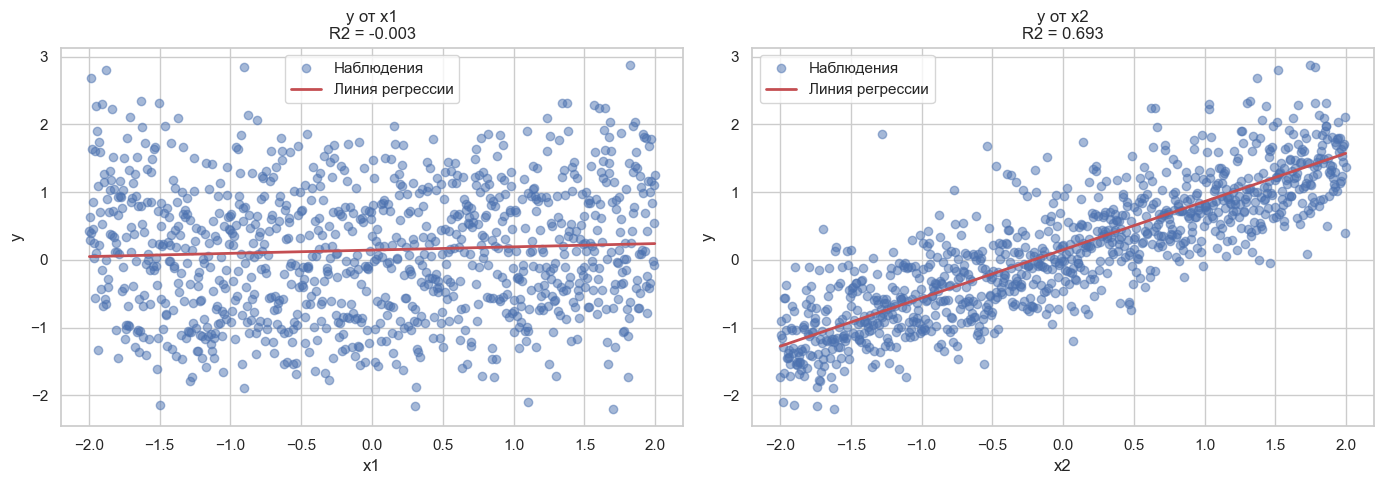

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, res in zip(axes, [res_x1, res_x2]):
    feat = res['feature']
    x_line = np.linspace(df[feat].min(), df[feat].max(), 100)
    y_line = res['a'] * x_line + res['b']
    ax.scatter(df[feat], df['y'], alpha=0.5, label='Наблюдения')
    ax.plot(x_line, y_line, 'r', linewidth=2, label='Линия регрессии')
    ax.set_xlabel(feat)
    ax.set_ylabel('y')
    ax.set_title(f"y от {feat}\nR2 = {res['R2']:.3f}")
    ax.legend()
plt.tight_layout()
plt.show()

**Что показывает график.** На левой панели (`y` от `x1`) облако точек не образует наклонной полосы: красная линия почти горизонтальна, поэтому линейная зависимость выражена слабо. На правой панели (`y` от `x2`) точки вытянуты вдоль возрастающей прямой, и линия регрессии проходит через центр облака. Это визуально подтверждает сильную положительную связь (`r ≈ 0.84`).

## 7. График разницы предсказанного и истинного значения по каждой точке

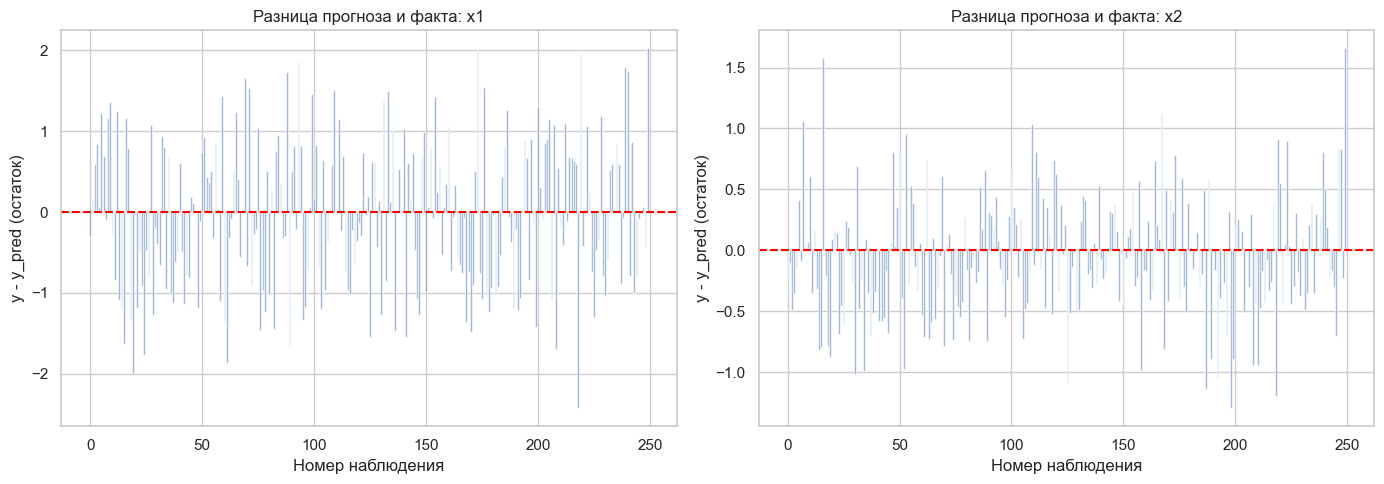

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, res in zip(axes, [res_x1, res_x2]):
    diff = (res['y_valid'] - res['y_pred']).values
    ax.axhline(0, color='red', linestyle='--')
    ax.bar(range(len(diff)), diff, alpha=0.7)
    ax.set_xlabel('Номер наблюдения')
    ax.set_ylabel('y - y_pred (остаток)')
    ax.set_title('Разница прогноза и факта: %s' % res['feature'])
plt.tight_layout()
plt.show()

**Что показывает график.** По горизонтальной оси отложен номер наблюдения в валидационной выборке, по вертикальной — остаток `y - y_pred`; красная пунктирная линия соответствует нулю. Для модели по `x2` столбцы в основном хаотично чередуются вокруг нуля, хотя есть отдельные крупные отклонения. Для модели по `x1` разброс остатков заметно больше, и они не выглядят чисто случайными: линейная модель не улавливает нелинейную составляющую связи.

## 8. График «факт — прогноз» (Prediction Error Plot)

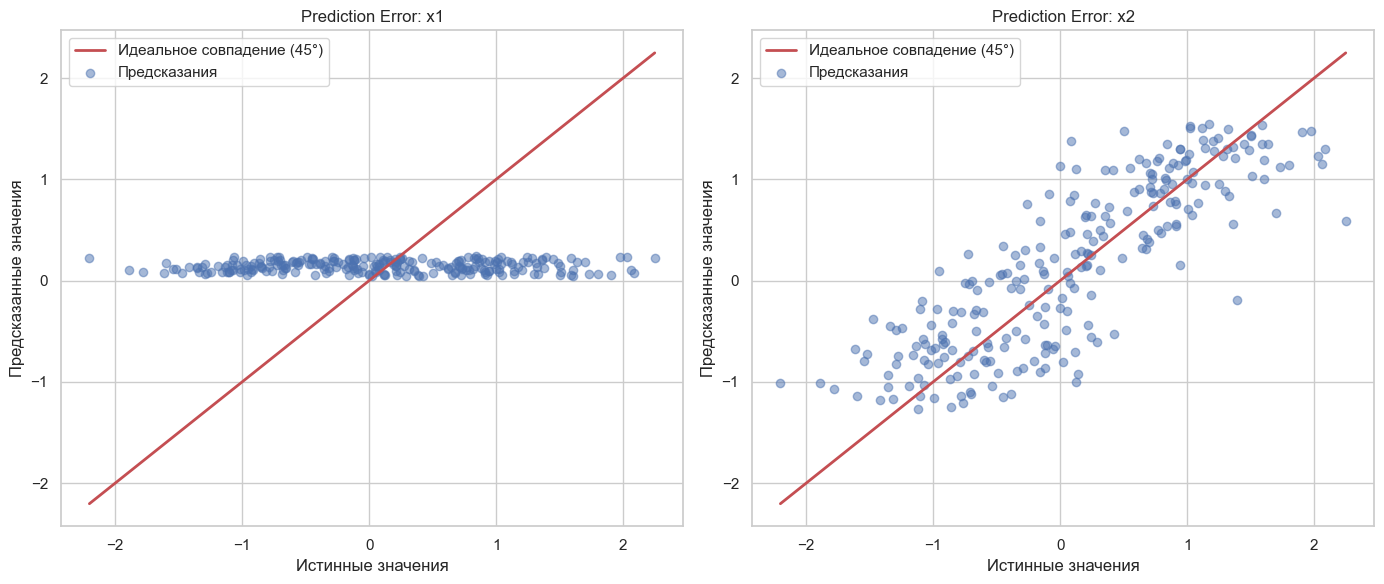

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, res in zip(axes, [res_x1, res_x2]):
    yv = res['y_valid'].values
    yp = res['y_pred']
    lims = [min(yv.min(), yp.min()), max(yv.max(), yp.max())]
    ax.plot(lims, lims, 'r', linewidth=2, label='Идеальное совпадение (45°)')
    ax.scatter(yv, yp, alpha=0.5, label='Предсказания')
    ax.set_xlabel('Истинные значения')
    ax.set_ylabel('Предсказанные значения')
    ax.set_title('Prediction Error: %s' % res['feature'])
    ax.legend()
plt.tight_layout()
plt.show()

**Что показывает график.** По осям отложены истинные и предсказанные значения, красная линия `y = x` под углом 45° соответствует идеальному совпадению, синие точки — предсказания модели. Для `x2` синие точки концентрируются вдоль диагонали, что говорит о хорошем качестве модели; отдельные точки отклоняются от неё на величину остатка. Для `x1` точки лежат далеко от диагонали и не образуют выраженного наклона — модель практически не объясняет изменчивость `y`.

## 9. Выводы по Части 1

**Связь признаков с целевой переменной.** Коэффициент корреляции Пирсона `r(x2, y) = 0.844` указывает на сильную положительную линейную связь: с увеличением `x2` значение `y` в среднем растёт. Для `x1` коэффициент `r(x1, y) = 0.050`, то есть линейная связь практически отсутствует. При этом нулевая корреляция не означает отсутствия связи вообще — для `x1` она может быть нелинейной, что проверяется в Части 2.

**Качество моделей.** В таблице метрик получены следующие результаты:

- `y = a * x2 + b`: MAE ≈ 0.4075, MSE ≈ 0.2564, RMSE ≈ 0.5064, R2 ≈ 0.693. Модель объясняет около 69% дисперсии `y`, а средняя абсолютная ошибка примерно вдвое меньше, чем у модели по `x1`.
- `y = a * x1 + b`: MAE ≈ 0.7652, MSE ≈ 0.8379, RMSE ≈ 0.9154, R2 ≈ −0.003. Отрицательный R2 означает, что модель предсказывает `y` хуже, чем простое среднее.

**Коэффициенты.** Для модели по `x2` получены `a ≈ 0.7128`, `b ≈ 0.1482`. Это значит, что при увеличении `x2` на 1 единицу `y` в среднем возрастает примерно на 0.71. Для модели по `x1` коэффициенты `a ≈ 0.0480`, `b ≈ 0.1438`, однако из-за R2 < 0 интерпретировать эту зависимость как рабочую нельзя.

**Что показали графики.**
- Диаграмма рассеяния с линией регрессии: для `x2` облако точек вытянуто вдоль возрастающей прямой, и линия регрессии хорошо проходит через его центр; для `x1` наклона практически нет.
- График остатков по точкам: для `x2` остатки в основном хаотично колеблются вокруг нуля, хотя есть отдельные крупные отклонения; для `x1` разброс остатков значительно больше и сравним с разбросом самой целевой переменной.
- График «факт — прогноз»: для `x2` точки концентрируются около диагонали 45°, для `x1` — далеко от неё и без выраженного наклона.

**Итог.** Для прогноза `y` по одному признаку `x2` подходит простая линейная регрессия: она даёт приемлемое качество и интерпретируемые коэффициенты. Признак `x1` в линейной модели непригоден; для него нужно искать нелинейную форму зависимости, чем мы займёмся в Части 2.

# Часть 2. Полиномиальная регрессия

## 1. Обоснование выбора признака

Полиномиальную регрессию целесообразно применять там, где связь **нелинейна**. Из Части&nbsp;1 известно, что связь `y` с `x2` линейна (R2 линейной модели уже ≈ 0.69, добавление степеней не улучшает результат). Связь `y` с `x1` линейной моделью не описывается (R2 ≈ 0), при этом на диаграмме рассеяния видна **параболическая (квадратичная)** зависимость. Значит, полиномиальную регрессию применяем к признаку **`x1`**.

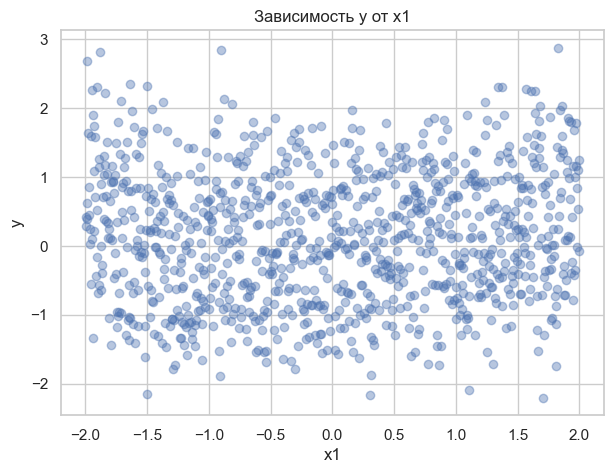

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(df['x1'], df['y'], alpha=0.4)
plt.xlabel('x1')
plt.ylabel('y')
plt.title('Зависимость y от x1')
plt.show()

## 2. Сравнение полиномов разной степени

Обучим полиномиальную регрессию для степеней 1–10 и сведём метрики в таблицу.

In [13]:
def poly_regression(feature, degree):
    x = df[[feature]].values
    y = df['y'].values
    x_train, x_valid, y_train, y_valid = train_test_split(
        x, y, test_size=0.25, random_state=RANDOM_STATE)

    poly = PolynomialFeatures(degree=degree)
    x_train_p = poly.fit_transform(x_train)
    x_valid_p = poly.transform(x_valid)

    model = LinearRegression()
    model.fit(x_train_p, y_train)
    y_train_pred = model.predict(x_train_p)
    y_valid_pred = model.predict(x_valid_p)

    return {
        'degree': degree, 'poly': poly, 'model': model,
        'y_train': y_train, 'y_valid': y_valid,
        'y_train_pred': y_train_pred, 'y_valid_pred': y_valid_pred,
        'R2_train': metrics.r2_score(y_train, y_train_pred),
        'R2_test': metrics.r2_score(y_valid, y_valid_pred),
        'MAE_train': metrics.mean_absolute_error(y_train, y_train_pred),
        'MAE_test': metrics.mean_absolute_error(y_valid, y_valid_pred),
    }

poly_results = [poly_regression('x1', d) for d in range(1, 11)]

poly_table = pd.DataFrame([{
    'Степень полинома': r['degree'],
    'R2train': r['R2_train'],
    'R2test': r['R2_test'],
    'MAEtrain': r['MAE_train'],
    'MAEtest': r['MAE_test'],
} for r in poly_results])
poly_table.round(4)

,Степень полинома,R2train,R2test,MAEtrain,MAEtest
0,1,0.0033,-0.0030,0.8053,0.7652
1,2,0.0268,0.0381,0.7978,0.7528
2,3,0.0287,0.0464,0.7961,0.7517
3,4,0.0381,0.0425,0.7927,0.7561
4,5,0.0390,0.0420,0.7934,0.7583
5,6,0.0400,0.0422,0.7928,0.7576
6,7,0.0401,0.0407,0.7928,0.7583
7,8,0.0401,0.0418,0.7927,0.7577
8,9,0.0405,0.0425,0.7922,0.7573
9,10,0.0446,0.0443,0.7903,0.7593


## 3. Визуализация полиномиальной регрессии (точки и линия регрессии)

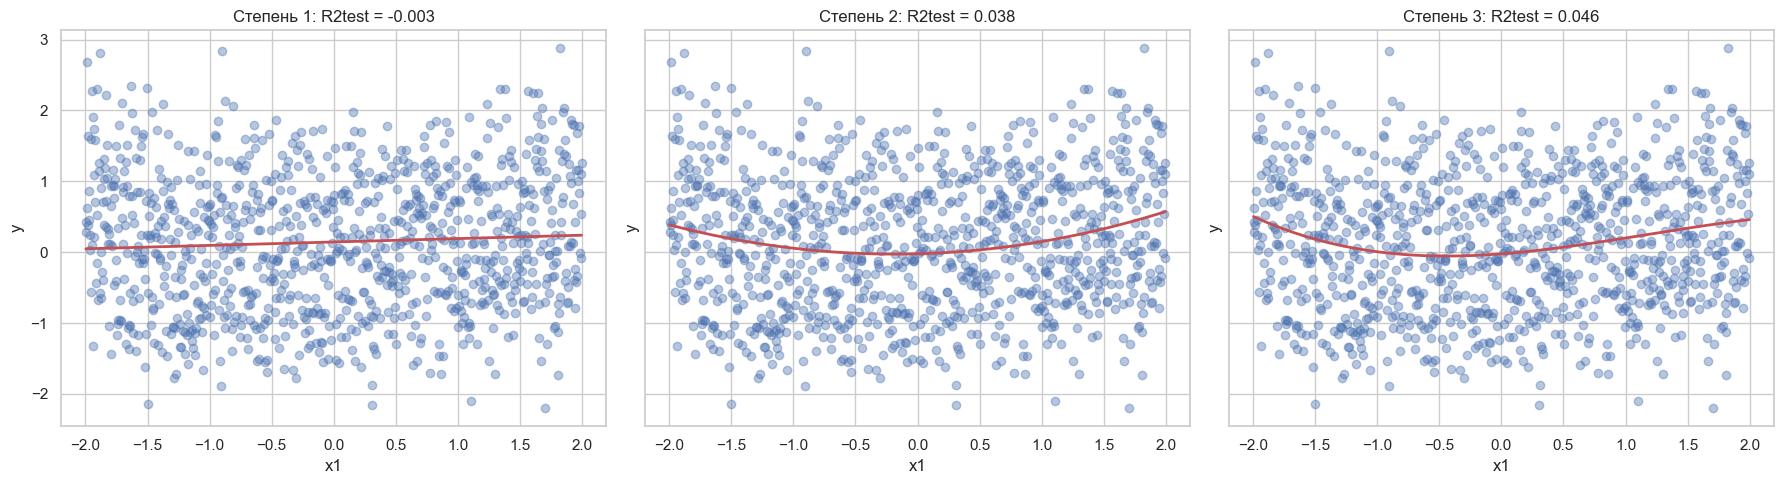

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, deg in zip(axes, [1, 2, 3]):
    r = poly_results[deg - 1]
    xs = np.linspace(df['x1'].min(), df['x1'].max(), 200).reshape(-1, 1)
    ys = r['model'].predict(r['poly'].transform(xs))
    ax.scatter(df['x1'], df['y'], alpha=0.4)
    ax.plot(xs, ys, 'r', linewidth=2)
    ax.set_xlabel('x1')
    ax.set_ylabel('y')
    ax.set_title('Степень %d: R2test = %.3f' % (deg, r['R2_test']))
plt.tight_layout()
plt.show()

**Что показывает график.** Три панели соответствуют степеням полинома 1, 2 и 3. При степени 1 линия прямая и не повторяет параболическую форму облака. При степенях 2–3 появляется изгиб, который лучше описывает зависимость: кривая проходит через «дно» параболы и поднимается к краям. При этом облако точек остаётся широким, поэтому даже лучшая кривая объясняет лишь несколько процентов дисперсии `y`: вклад `x1` в общую вариативность невелик.

## 4. Выводы по Части 2

**Почему выбран `x1`.** Связь `y` с `x2` уже хорошо описывается линейной моделью (R2 ≈ 0.693), поэтому усложнение полиномом здесь не требуется. Связь `y` с `x1` линейной моделью не описывается (R2 ≈ 0), но на диаграмме рассеяния видна параболическая зависимость. Поэтому полиномиальную регрессию применяем именно к `x1`.

**Результаты по степеням.** Ключевые строки таблицы:

| Степень | R2 train | R2 test | MAE test |
|---:|---:|---:|---:|
| 1 | 0.0033 | −0.0030 | 0.7652 |
| 2 | 0.0268 | 0.0381 | 0.7528 |
| 3 | 0.0287 | 0.0464 | 0.7517 |
| 4 | 0.0381 | 0.0425 | 0.7561 |
| 10 | 0.0446 | 0.0443 | 0.7593 |

Лучший результат на валидации даёт **степень 3**: R2 test ≈ 0.0464 и минимальный MAE test ≈ 0.7517. Степень 2 близка к ней (R2 test ≈ 0.0381, MAE test ≈ 0.7528), но проще и поэтому предпочтительнее, если нет дополнительных требований к точности. При степени 1 модель недообучается и не улавливает параболу: R2 test отрицательный.

**Переобучение.** В данном наборе выраженного переобучения по таблице не видно: train- и test-метрики для степеней 2–10 отличаются слабо, а степень 10 не даёт выигрыша на тесте. Это объясняется тем, что вклад `x1` в общую дисперсию `y` мал. Теоретически при слишком высокой степени полином начинает подстраиваться под случайный шум: train-R2 растёт, test-R2 падает, а коэффициенты становятся неустойчивыми. Поэтому на практике степень выбирают по кросс-валидации, а не по train-качеству; для этих данных достаточно степени 2–3.

**Что показывает график.** На трёх панелях видно, как меняется форма линии: степень 1 даёт прямую, степени 2–3 — параболу, которая лучше повторяет облако точек. При этом даже лучшая кривая объясняет лишь несколько процентов дисперсии `y`, потому что основной вклад в `y` даёт другой признак — `x2`.

**Итог.** Полиномиальная регрессия по `x1` действительно улучшает линейную модель, но улучшение небольшое: R2 test растёт с ≈ 0 до ≈ 0.046. Если прогнозировать `y` только по `x1`, оптимальна степень 2–3; если доступны оба признака, разумнее строить множественную регрессию с `x2` и, возможно, нелинейным членом по `x1`.

# Часть 3. Решение задачи регрессии различными методами

## 1. Загрузка набора данных `salary.csv`

Целевая переменная — **`salary`** (годовая зарплата). Остальные столбцы — признаки.

Признаки: `age`, `income`, `experience`, `score_test`, `hours_worked`, `distance_to_work`, `savings`, `debt` (числовые) и `education`, `city`, `job_type`, `marital_status`, `car`, `remote_work` (категориальные).

In [15]:
df_sal = pd.read_csv('salary.csv')
print('Размер набора данных:', df_sal.shape)
display(df_sal.head())
display(df_sal.describe())
print('Пропуски:')
print(df_sal.isna().sum().sum(), 'шт.')

Размер набора данных: (1500, 15)


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


Пропуски:
0 шт.


## 2. Визуализация целевой переменной (гистограмма и boxplot)

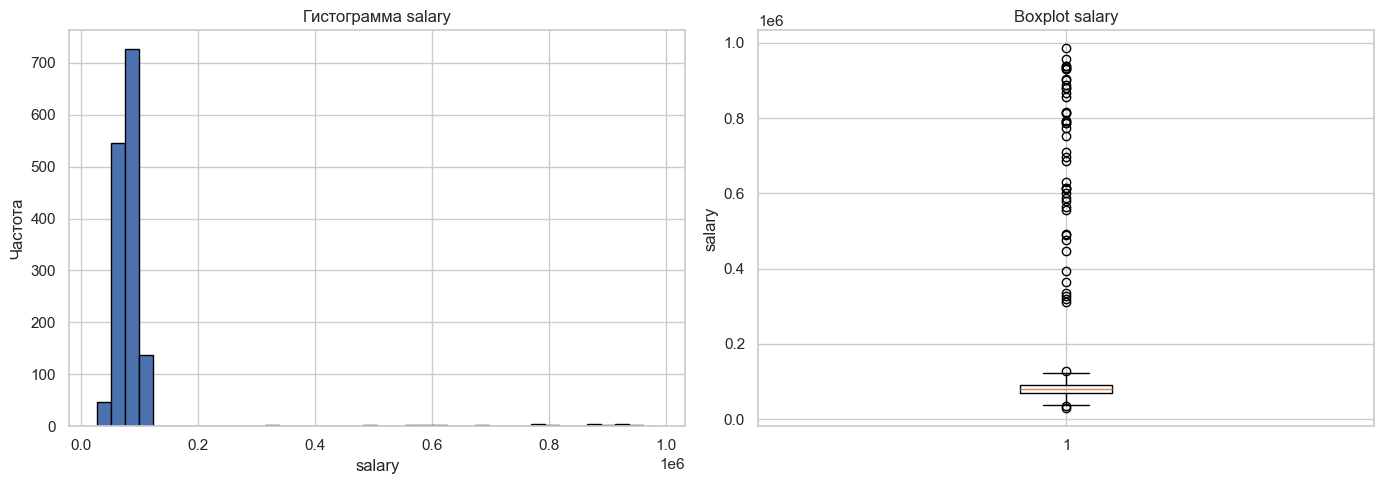

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_sal['salary'], bins=40, edgecolor='black')
axes[0].set_title('Гистограмма salary')
axes[0].set_xlabel('salary')
axes[0].set_ylabel('Частота')
axes[1].boxplot(df_sal['salary'])
axes[1].set_title('Boxplot salary')
axes[1].set_ylabel('salary')
plt.tight_layout()
plt.show()

**Что показывают графики.** Гистограмма `salary` имеет длинный правый хвост: большинство значений сосредоточено примерно в диапазоне 60–100 тыс., но встречаются отдельные значения до ~986 тыс. Boxplot подтверждает асимметрию: медиана ≈ 80.3 тыс., верхний квартиль ≈ 91.6 тыс., а выше верхней границы «усов» расположено много выбросов. Такие значения могут сильно смещать оценки линейной модели, поэтому целевую переменную необходимо очистить.

## 3. Кодирование признаков и обработка выбросов

- Категориальные признаки кодируем **прямым кодированием** (`pd.get_dummies`, `drop_first=True`) для устранения ловушки фиктивных переменных.
- Выбросы целевой переменной удаляем по правилу **IQR** (1.5 · IQR).

In [17]:
def remove_outliers_iqr(data, columns):
    data = data.copy()
    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        data = data[(data[col] >= lower) & (data[col] <= upper)]
    return data

print('До обработки выбросов:', df_sal.shape)
df_sal_clean = remove_outliers_iqr(df_sal, ['salary'])
print('После удаления выбросов salary:', df_sal_clean.shape)
cat_cols = ['education', 'city', 'job_type', 'marital_status', 'car', 'remote_work']
df_sal_clean = pd.get_dummies(df_sal_clean, columns=cat_cols, drop_first=True)
print('Размер после кодирования:', df_sal_clean.shape)

print('\nОписательные статистики после очистки:')
display(df_sal_clean['salary'].describe())
display(df_sal_clean.head())

До обработки выбросов: (1500, 15)
После удаления выбросов salary: (1452, 15)
Размер после кодирования: (1452, 24)

Описательные статистики после очистки:


count      1452.000000
mean      80118.196424
std       15153.685036
min       38091.827270
25%       69233.798250
50%       80024.802586
75%       90491.686285
max      122930.173198
Name: salary, dtype: float64

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary,education_High School,...,city_New York,city_Phoenix,job_type_Finance,job_type_Healthcare,job_type_IT,job_type_Retail,marital_status_Married,marital_status_Single,car_Yes,remote_work_Yes
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,106233.833479,False,...,False,False,True,False,False,False,False,True,True,True
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,87205.291042,True,...,False,False,False,False,False,True,False,True,False,True
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,69369.283522,False,...,False,False,True,False,False,False,True,False,True,False
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,76587.116955,False,...,False,False,False,False,True,False,True,False,True,False
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,71023.148842,False,...,False,True,False,False,True,False,True,False,False,False


## 4. Визуализация после обработки

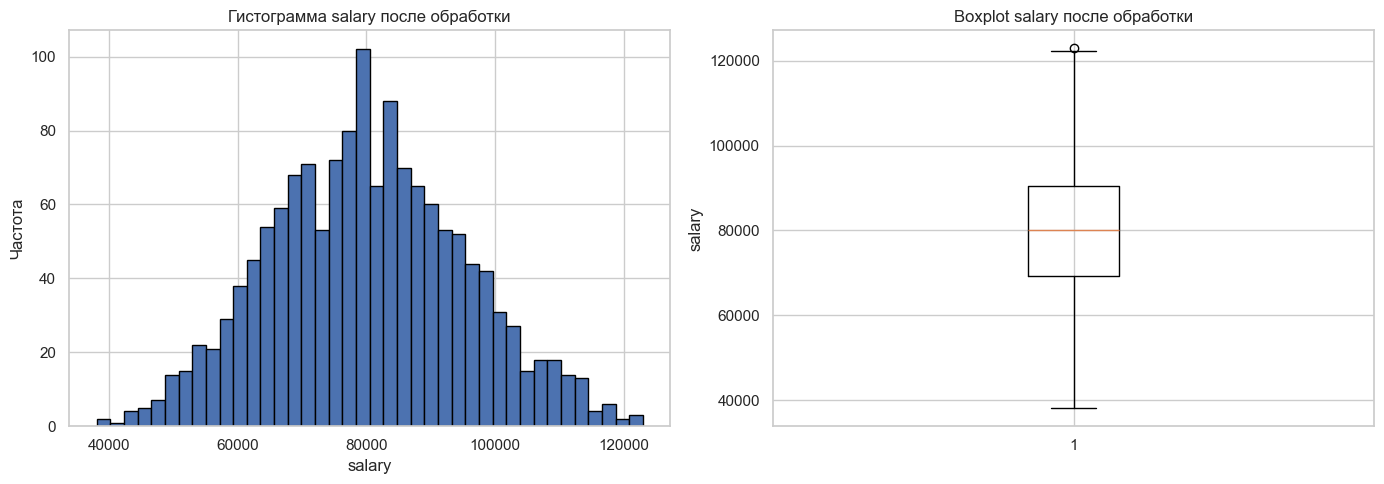

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_sal_clean['salary'], bins=40, edgecolor='black')
axes[0].set_title('Гистограмма salary после обработки')
axes[0].set_xlabel('salary')
axes[0].set_ylabel('Частота')
axes[1].boxplot(df_sal_clean['salary'])
axes[1].set_title('Boxplot salary после обработки')
axes[1].set_ylabel('salary')
plt.tight_layout()
plt.show()

**Что показывают графики.** После удаления выбросов по правилу IQR гистограмма стала заметно компактнее и симметричнее, длинный правый хвост исчез. На boxplot уменьшились разброс и верхняя граница, явных экстремальных значений не осталось. После очистки `salary` имеет среднее ≈ 80 тыс., стандартное отклонение ≈ 15 тыс., минимум ≈ 38 тыс. и максимум ≈ 123 тыс.; асимметрия снизилась до ≈ 0.10. Это уменьшает влияние крупных ошибок на обучение, хотя часть информации о высоких зарплатах теряется.

## 5. Матрица диаграмм рассеяния

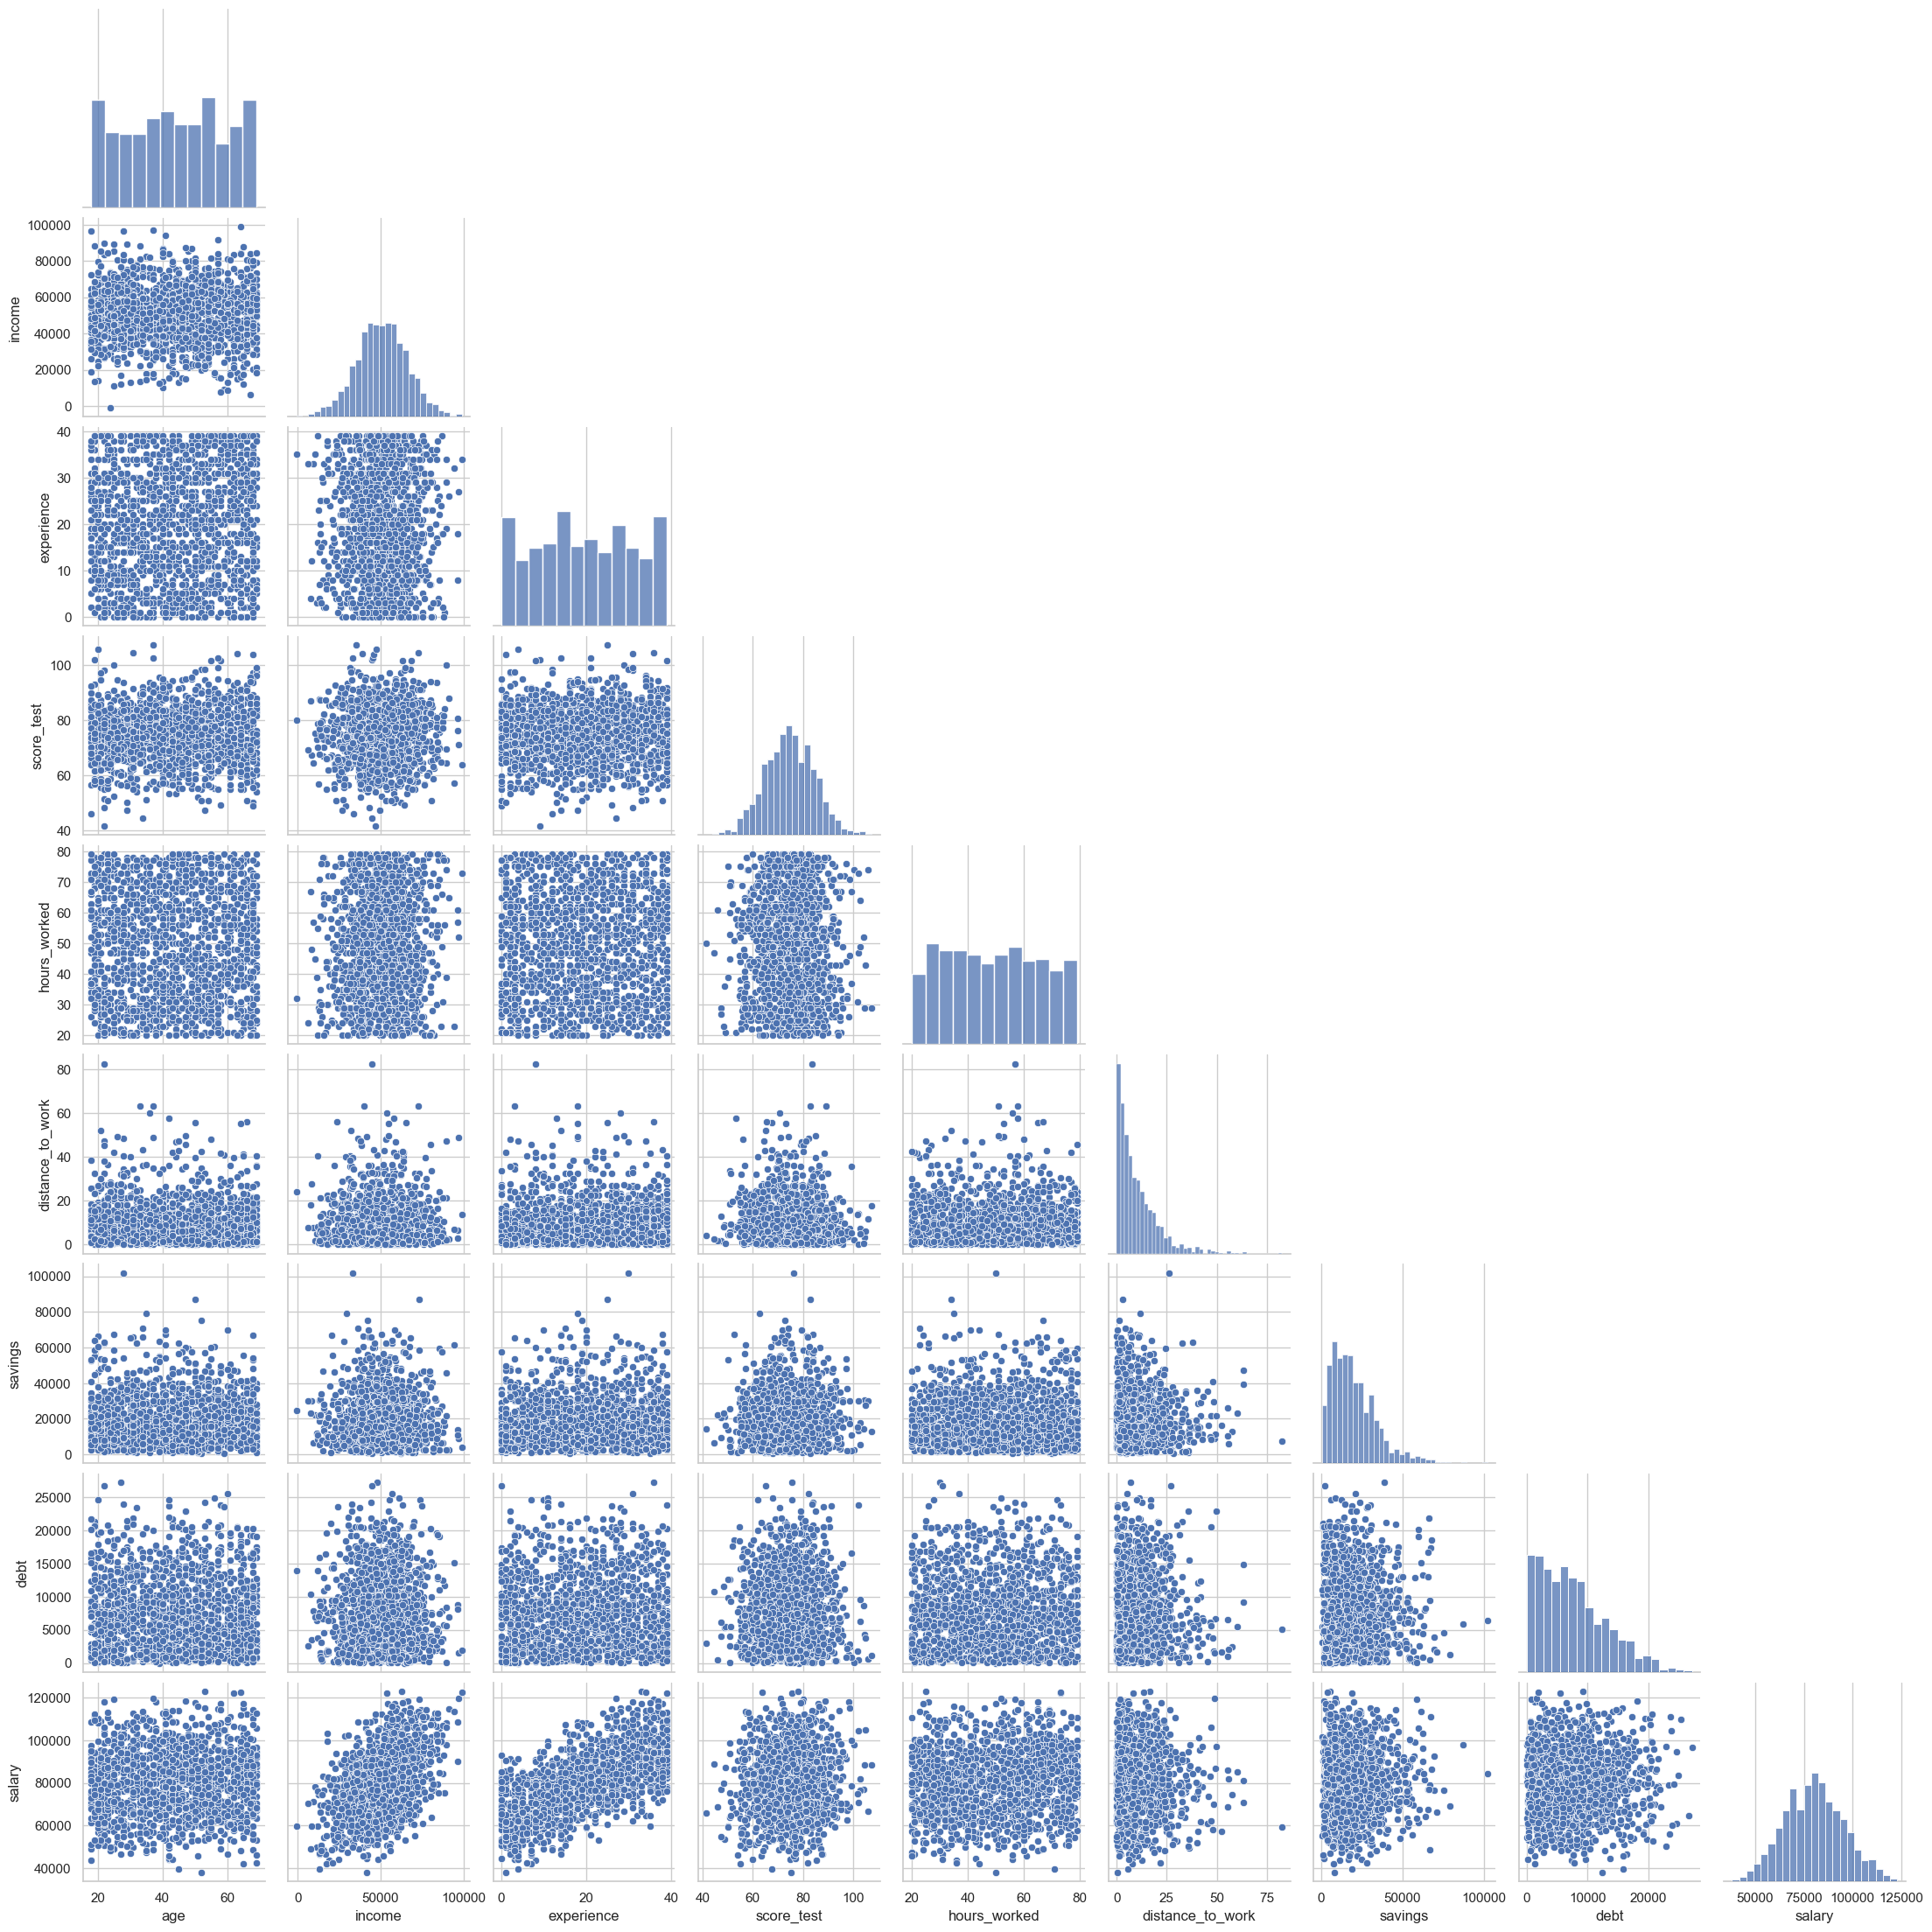

In [19]:
num_cols = ['age', 'income', 'experience', 'score_test', 'hours_worked',
            'distance_to_work', 'savings', 'debt', 'salary']
sns.pairplot(df_sal_clean[num_cols], corner=True)
plt.show()

**Что показывает график.** Матрица диаграмм рассеяния позволяет быстро оценить попарные связи. С `salary` заметнее всего связаны `income`, `experience` и `score_test`: облака вытянуты вдоль возрастающих прямых. Связи с `age`, `hours_worked`, `distance_to_work`, `savings` и `debt` выражены слабее. Между некоторыми признаками (например, `income` и `experience`) также видна положительная связь, что важно учитывать при интерпретации коэффициентов множественной регрессии.

## 6. Разделение данных и масштабирование

Разделяем на обучающую (75%) и валидационную (25%) выборки. `StandardScaler` обучаем **только на train** и применяем к train и valid — это исключает утечку данных.

In [20]:
x = df_sal_clean.drop('salary', axis=1).astype(float)
y = df_sal_clean['salary']

x_train, x_valid, y_train, y_valid = train_test_split(
    x, y, test_size=0.25, random_state=RANDOM_STATE)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)   # fit + transform на train
x_valid_scaled = scaler.transform(x_valid)       # только transform на valid

print('Train:', x_train_scaled.shape, 'Valid:', x_valid_scaled.shape)

Train: (1089, 23) Valid: (363, 23)


## 7. Вспомогательная функция оценки модели

In [21]:
def evaluate(model, x_tr, y_tr, x_va, y_va):
    model.fit(x_tr, y_tr)
    pred = model.predict(x_va)
    return {
        'model': model,
        'pred': pred,
        'MAE': metrics.mean_absolute_error(y_va, pred),
        'MSE': metrics.mean_squared_error(y_va, pred),
        'RMSE': np.sqrt(metrics.mean_squared_error(y_va, pred)),
        'R2': metrics.r2_score(y_va, pred),
        'MAPE': np.mean(np.abs((y_va - pred) / y_va)) * 100,
    }

## 8. Модель линейной регрессии

In [22]:
lin_res = evaluate(LinearRegression(), x_train_scaled, y_train, x_valid_scaled, y_valid)

print('LinearRegression:')
print(f"MAE  = {lin_res['MAE']:.2f}")
print(f"MSE  = {lin_res['MSE']:.2f}")
print(f"RMSE = {lin_res['RMSE']:.2f}")
print(f"R2   = {lin_res['R2']:.4f}")
print(f"MAPE = {lin_res['MAPE']:.2f}%")

LinearRegression:
MAE  = 4915.83
MSE  = 37419468.78
RMSE = 6117.15
R2   = 0.8591
MAPE = 6.55%


## 9. Датафрейм с истинными и предсказанными значениями

In [23]:
df_match = pd.DataFrame({'Actual': y_valid.values, 'Predicted': lin_res['pred']})
df_match['Difference'] = df_match['Actual'] - df_match['Predicted']
display(df_match.head(15))

,Actual,Predicted,Difference
0,90772.277599,90022.654163,749.623436
1,84475.346122,88404.502189,-3929.156067
2,67777.676332,63984.471940,3793.204392
3,110650.659849,106266.109689,4384.550159
4,68551.168300,67802.019474,749.148826
5,79324.467916,70529.790614,8794.677302
6,59571.086625,53701.664738,5869.421887
7,90409.785269,85380.771857,5029.013412
8,92280.580124,94861.867162,-2581.287038
9,79311.102051,80719.001579,-1407.899528


## 10. Коэффициенты модели и важность признаков

,Feature,Coefficient
0,experience,10293.710290
1,income,7334.341444
2,education_PhD,4209.361178
3,education_Master,2204.744462
4,education_High School,-2141.978406
5,job_type_IT,1752.592000
6,score_test,1093.627752
7,job_type_Finance,719.190674
8,city_New York,679.581967
9,car_Yes,-515.193342


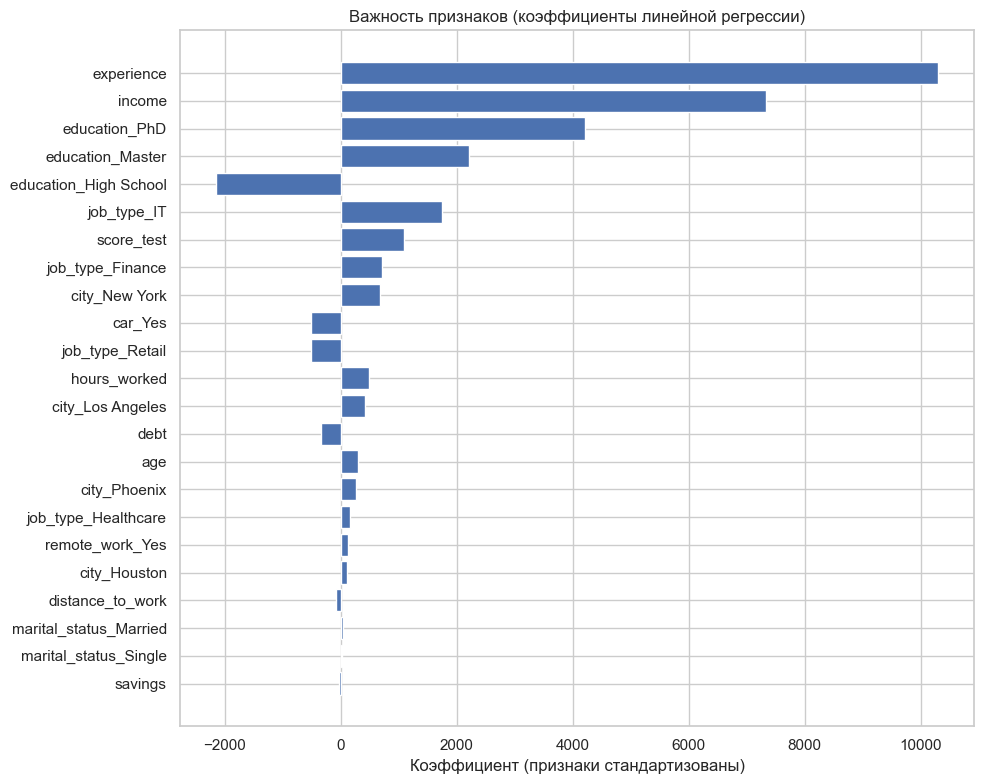

In [24]:
coef_df = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': lin_res['model'].coef_,
})
coef_df = coef_df.sort_values(by='Coefficient', key=np.abs, ascending=False).reset_index(drop=True)
display(coef_df)

plt.figure(figsize=(10, 8))
plt.barh(coef_df['Feature'], coef_df['Coefficient'])
plt.title('Важность признаков (коэффициенты линейной регрессии)')
plt.xlabel('Коэффициент (признаки стандартизованы)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Что показывает график.** Столбцы отсортированы по модулю коэффициента. Так как признаки стандартизованы, длина столбца показывает изменение `salary` (в долларах) при увеличении соответствующего признака на одно стандартное отклонение. Наибольший положительный вклад дают `experience` (+10294), `income` (+7334), `education_PhD` (+4209), `education_Master` (+2205), `job_type_IT` (+1753) и `score_test` (+1094). Отрицательные коэффициенты у `education_High School` (−2142 относительно базового уровня `Bachelor`), `car_Yes` (−515), `job_type_Retail` (−502) и `debt` (−343). Коэффициенты около нуля (`savings`, часть городов, `marital_status`) означают слабое влияние после учёта остальных признаков.

## 11. Визуализация: фактические и предсказанные значения

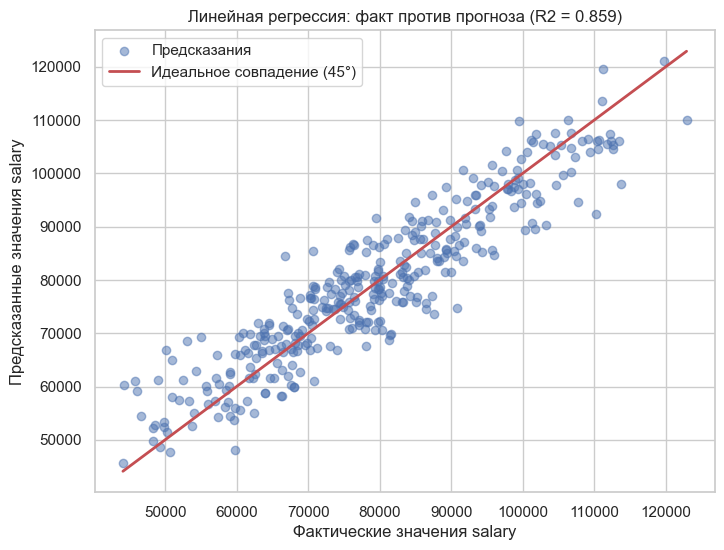

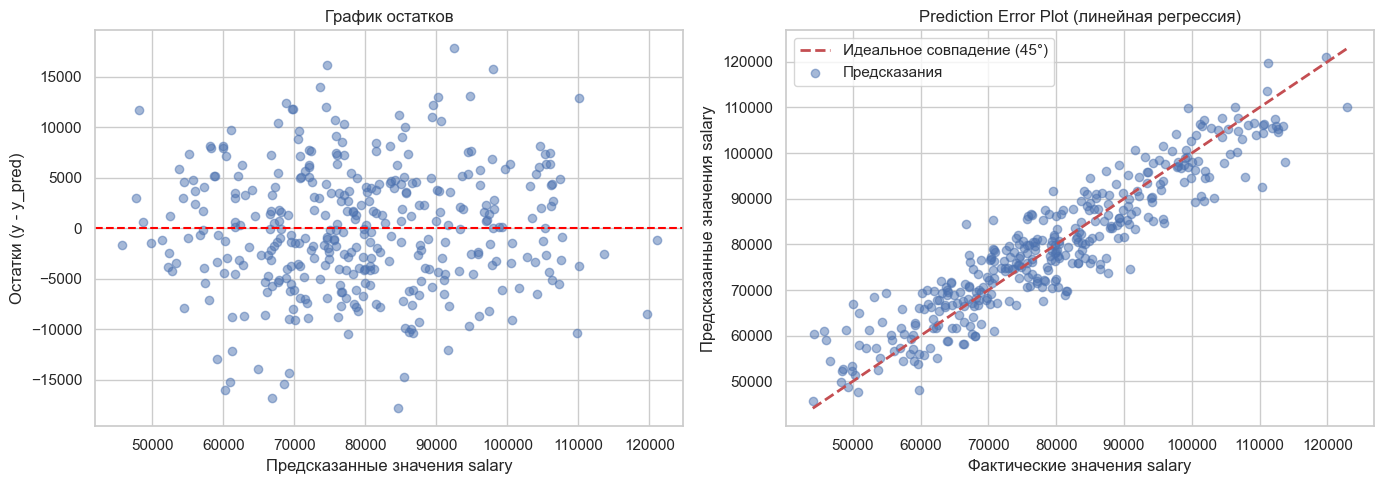

In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(y_valid, lin_res['pred'], alpha=0.5, label='Предсказания')
lims = [y_valid.min(), y_valid.max()]
plt.plot(lims, lims, 'r', linewidth=2, label='Идеальное совпадение (45°)')
plt.xlabel('Фактические значения salary')
plt.ylabel('Предсказанные значения salary')
plt.title(f"Линейная регрессия: факт против прогноза (R2 = {lin_res['R2']:.3f})")
plt.legend()
plt.show()


# График остатков и Prediction Error (линейная регрессия)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График остатков
resid = y_valid - lin_res['pred']
axes[0].axhline(0, color='red', linestyle='--')
axes[0].scatter(lin_res['pred'], resid, alpha=0.5)
axes[0].set_xlabel('Предсказанные значения salary')
axes[0].set_ylabel('Остатки (y - y_pred)')
axes[0].set_title('График остатков')

# Prediction Error Plot
lims = [y_valid.min(), y_valid.max()]
axes[1].plot(lims, lims, 'r', linestyle='--', linewidth=2, label='Идеальное совпадение (45°)')
axes[1].scatter(y_valid, lin_res['pred'], alpha=0.5, label='Предсказания')
axes[1].set_xlabel('Фактические значения salary')
axes[1].set_ylabel('Предсказанные значения salary')
axes[1].set_title('Prediction Error Plot (линейная регрессия)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Что показывают графики.**
- Точки «факт — прогноз» для линейной модели группируются вокруг красной диагонали: модель в целом правильно воспроизводит уровень зарплаты. Остатки в среднем близки к нулю, хотя отдельные наблюдения отклоняются на несколько тысяч долларов. `R2 ≈ 0.86` означает, что модель объясняет около 86% дисперсии `salary`; `MAPE ≈ 6.6%` — средняя относительная ошибка прогноза.
- На левом графике остатки хаотично рассеяны вокруг горизонтальной линии 0 без выраженной закономерности — это говорит об адекватности линейной модели.
- На правом графике точки группируются вдоль диагонали y=x. Отсутствие систематического тренда в остатках подтверждает, что модель хорошо описывает зависимость.

## 12. Регрессия методом k-ближайших соседей и деревом решений

Подбираем разумные гиперпараметры: `n_neighbors` для kNN (по результатам перебора шага сетки). Для дерева решений подберём оптимальную `max_depth`.

In [ ]:
# Подбор оптимального количества соседей k для KNN
k_values = [3, 5, 7, 9, 11, 15, 20, 25]
knn_grid = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(x_train_scaled, y_train)

    pred_tr = knn.predict(x_train_scaled)
    pred_va = knn.predict(x_valid_scaled)

    knn_grid.append({
        'k': k,
        'R2_train': metrics.r2_score(y_train, pred_tr),
        'R2_valid': metrics.r2_score(y_valid, pred_va),
        'MAE_train': metrics.mean_absolute_error(y_train, pred_tr),
        'MAE_valid': metrics.mean_absolute_error(y_valid, pred_va)
    })

knn_grid_df = pd.DataFrame(knn_grid)

# Выбираем k с наибольшим R² на валидационной выборке
best_k = int(
    knn_grid_df.sort_values(
        by='R2_valid', ascending=False
    ).iloc[0]['k']
)

print('Оптимальное количество соседей по R2_valid:', best_k)

# Оцениваем итоговую модель с найденным k
knn_res = evaluate(
    KNeighborsRegressor(n_neighbors=best_k),
    x_train_scaled, y_train,
    x_valid_scaled, y_valid
)

# Подбор оптимальной глубины дерева решений
depths = range(1, 13)
tree_grid = []
for d in depths:
    tr = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
    tr.fit(x_train_scaled, y_train)
    pred_tr = tr.predict(x_train_scaled)
    pred_va = tr.predict(x_valid_scaled)
    tree_grid.append({'max_depth': d, 'R2_train': metrics.r2_score(y_train, pred_tr), 'R2_valid': metrics.r2_score(y_valid, pred_va), 'MAE_train': metrics.mean_absolute_error(y_train, pred_tr), 'MAE_valid': metrics.mean_absolute_error(y_valid, pred_va)})
tree_grid_df = pd.DataFrame(tree_grid)
best_d = int(tree_grid_df.sort_values(by='R2_valid', ascending=False).iloc[0]['max_depth'])
print('Оптимальная глубина по R2_valid:', best_d)

tree_res = evaluate(DecisionTreeRegressor(max_depth=best_d, random_state=RANDOM_STATE),
                    x_train_scaled, y_train, x_valid_scaled, y_valid)

print(f"KNeighborsRegressor (k={best_k}): MAE={knn_res['MAE']:.2f} RMSE={knn_res['RMSE']:.2f} R2={knn_res['R2']:.4f} MAPE={knn_res['MAPE']:.2f}%")
print(f"DecisionTreeRegressor (max_depth={best_d}): MAE={tree_res['MAE']:.2f} RMSE={tree_res['RMSE']:.2f} R2={tree_res['R2']:.4f} MAPE={tree_res['MAPE']:.2f}%")

Оптимальное количество соседей по R2_valid: 11
Оптимальная глубина по R2_valid: 7
KNeighborsRegressor (k=11): MAE=9378.13 RMSE=11655.66 R2=0.4884 MAPE=12.69%
DecisionTreeRegressor (max_depth=7): MAE=7326.37 RMSE=8977.67 R2=0.6965 MAPE=9.70%


## 13. Сравнение методов

In [31]:
comparison = pd.DataFrame({
    'Модель': [
        'LinearRegression',
        'KNeighborsRegressor (k=11)',
        'DecisionTreeRegressor (max_depth=7)',
    ],
    'MAE':  [lin_res['MAE'],  knn_res['MAE'],  tree_res['MAE']],
    'MSE':  [lin_res['MSE'],  knn_res['MSE'],  tree_res['MSE']],
    'RMSE': [lin_res['RMSE'], knn_res['RMSE'], tree_res['RMSE']],
    'R2':   [lin_res['R2'],   knn_res['R2'],   tree_res['R2']],
    'MAPE': [lin_res['MAPE'], knn_res['MAPE'], tree_res['MAPE']],
})
comparison.round(4).sort_values(by='R2', ascending=False).reset_index(drop=True)

,Модель,MAE,MSE,RMSE,R2,MAPE
0,LinearRegression,4915.8320,3.741947e+07,6117.1455,0.8591,6.5526
1,DecisionTreeRegressor (max_depth=7),7326.3726,8.059847e+07,8977.6651,0.6965,9.7036
2,KNeighborsRegressor (k=11),9378.1349,1.358545e+08,11655.6623,0.4884,12.6917


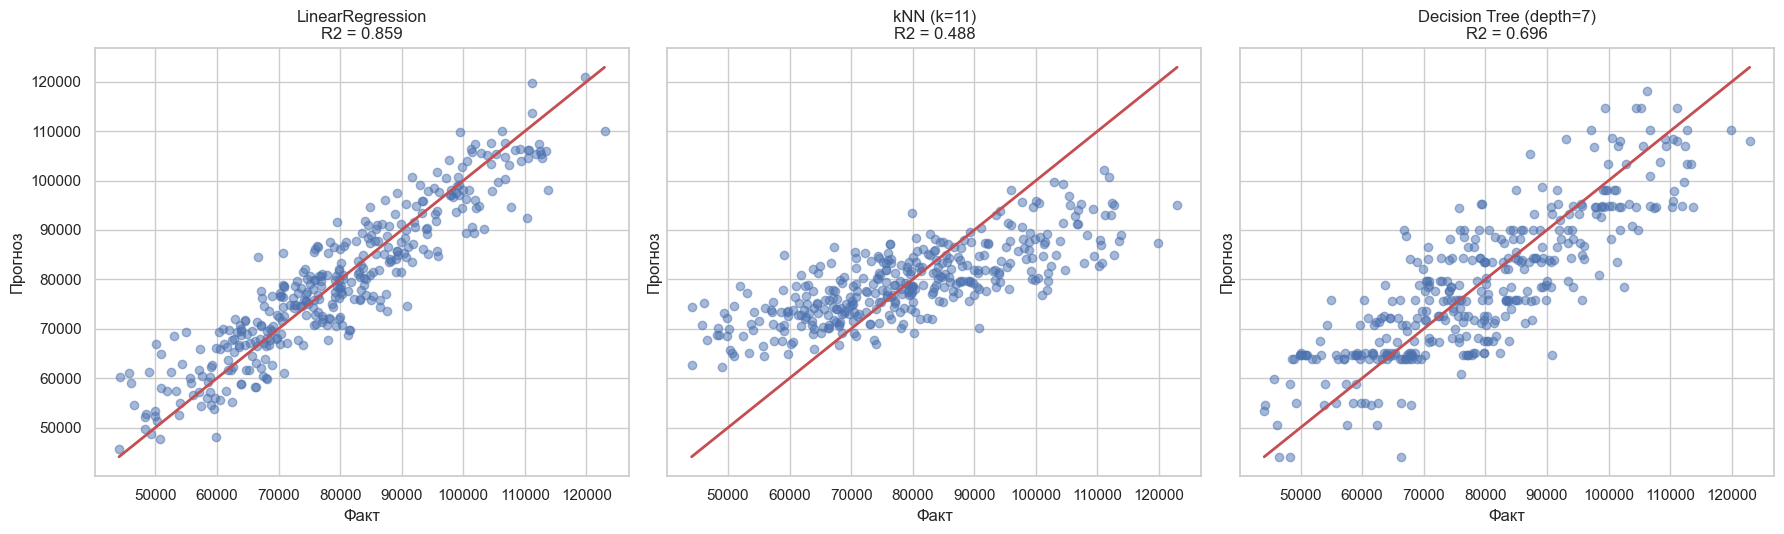

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
models = [('LinearRegression', lin_res), ('kNN (k=11)', knn_res), ('Decision Tree (depth=7)', tree_res)]
lims = [y_valid.min(), y_valid.max()]
for ax, (name, res) in zip(axes, models):
    ax.scatter(y_valid, res['pred'], alpha=0.5)
    ax.plot(lims, lims, 'r', linewidth=2)
    ax.set_xlabel('Факт')
    ax.set_ylabel('Прогноз')
    ax.set_title(f"{name}\nR2 = {res['R2']:.3f}")
plt.tight_layout()
plt.show()

**Что показывает график.** На трёх панелях сопоставлены «факт — прогноз» для линейной регрессии, дерева решений и kNN. У линейной модели облако наиболее узкое и близко к диагонали (`R2 ≈ 0.86`), у дерева оно шире и заметны ступенчатые отклонения (`R2 ≈ 0.70`), у kNN — самое широкое (`R2 ≈ 0.48`). Это визуально подтверждает таблицу метрик: линейная модель лучше всего описывает зависимость зарплаты от признаков.

## 14. Выводы по Части 3

**Данные и предобработка.** Исходный набор содержит 1500 наблюдений и 15 столбцов, пропусков нет. Целевая переменная `salary` сильно скошена вправо: медиана ≈ 80.3 тыс., верхний квартиль ≈ 91.6 тыс., максимум ≈ 985.6 тыс. После удаления выбросов по правилу IQR осталось 1452 наблюдения; после прямого кодирования категориальных признаков (`drop_first=True`) получилось 24 столбца. После очистки `salary` имеет среднее ≈ 80.1 тыс., стандартное отклонение ≈ 15.2 тыс., минимум ≈ 38.1 тыс., максимум ≈ 122.9 тыс. и асимметрию ≈ 0.10. `StandardScaler` обучался только на train (1089 наблюдений), а к validation (363 наблюдения) применялся только `transform` — утечки данных нет.

**Сравнение моделей.**

**Пояснения к метрикам:**
- **MAE** (Mean Absolute Error) — средняя абсолютная ошибка. Показывает, в среднем на сколько единиц модель ошибается при прогнозе `salary`.
- **MSE** (Mean Squared Error) — среднеквадратичная ошибка. Сильнее штрафует крупные промахи за счёт возведения отклонений в квадрат.
- **RMSE** (Root Mean Squared Error) — корень из MSE. Имеет те же единицы измерения, что и целевая переменная, поэтому удобнее для интерпретации.
- **R²** (коэффициент детерминации) — доля дисперсии `salary`, которую модель смогла объяснить. Чем ближе к 1, тем лучше.
- **MAPE** (Mean Absolute Percentage Error) — средняя абсолютная процентная ошибка. Показывает ошибку в процентах, наиболее наглядна для практической оценки.

| Модель | MAE | RMSE | R2 | MAPE |
|---|---:|---:|---:|---:|
| LinearRegression | 4915.83 | 6117.15 | 0.8591 | 6.55% |
| DecisionTreeRegressor (max_depth=7) | 7326.37 | 8977.67 | 0.6965 | 9.70% |
| KNeighborsRegressor (k=11) | 9378.13 | 11719.94 | 0.4884 | 12.69% |

Сравнив результаты, можно сделать вывод, что **линейная регрессия** показала наилучшее качество по всем метрикам: наименьшие MAE, RMSE, MAPE и наибольший R². Модель объясняет около 86% дисперсии `salary`, а средняя относительная ошибка составляет ~6,55%. Дерево решений и kNN уступают ей по точности. После one-hot-кодирования признаковое пространство для kNN стало разреженным, из-за чего евклидово расстояние перестало хорошо отражать близость наблюдений. Таким образом, для данного набора данных после предобработки связь между признаками и зарплатой преимущественно линейная, поэтому линейная регрессия является наиболее предпочтительной.

**Коэффициенты и важность признаков.** Так как числовые признаки стандартизованы, коэффициент линейной регрессии показывает, на сколько изменится `salary` при увеличении данного признака на одно стандартное отклонение при прочих равных условиях.

- **Положительный коэффициент** — при увеличении признака зарплата в среднем растёт.
- **Отрицательный коэффициент** — при увеличении признака зарплата в среднем снижается.

Для числовых признаков это прямолинейно: например, `debt` имеет коэффициент −343, значит при увеличении задолженности на одно стандартное отклонение `salary` в среднем уменьшается на ~343 при прочих равных.

Для категориальных признаков, закодированных с помощью `get_dummies(drop_first=True)`, один из уровней каждой переменной был удалён и стал **базовой категорией**. Коэффициент при фиктивном признаке показывает, насколько зарплата отличается от этой базовой категории при прочих равных.

Наибольший положительный вклад дают `experience` (+10294), `income` (+7334), `education_PhD` (+4209), `education_Master` (+2205), `job_type_IT` (+1753) и `score_test` (+1094). Отрицательные коэффициенты наблюдаются у `education_High School` (−2142) — при прочих равных у сотрудника со средним образованием зарплата в среднем на ~2142 ниже, чем у сотрудника с `Bachelor` (базовый уровень), `car_Yes` (−515) — ниже относительно базовой категории `car_No`, `job_type_Retail` (−502) — ниже относительно базовой категории для `job_type`, `debt` (−343) — как указано выше.

Признаки с коэффициентами около нуля (`savings`, часть городов, `marital_status`) после учёта остальных переменных почти не влияют на прогноз. Следует помнить, что это ассоциации, а не доказательство причинного влияния, а коррелированные признаки (`income` и `experience`) делят между собой вклад.

**Что показали графики.**
- Гистограмма и boxplot до обработки выявили сильную правостороннюю асимметрию и большое число выбросов `salary`; после удаления выбросов распределение стало компактным и почти симметричным.
- Матрица диаграмм рассеяния показала, что с `salary` заметнее всего связаны `income`, `experience` и `score_test`; остальные числовые признаки связаны слабее.
- Столбчатая диаграмма коэффициентов подтвердила, что основные драйверы зарплаты — опыт, доход, уровень образования и сфера деятельности.
- График «факт — прогноз» для линейной модели показал плотное облако вокруг диагонали 45° и отсутствие выраженного тренда в остатках.
- Сравнительные графики для трёх моделей наглядно показали, что линейная регрессия даёт самое узкое облако вокруг диагонали, дерево — более широкое, а kNN — самое широкое.
- Дополнительная диагностика остатков и ошибок прогноза подтвердила адекватность линейной модели: остатки распределены вокруг нуля, а облако «факт — прогноз» близко к диагонали.

**Итог.** Для данной задачи целесообразно использовать линейную регрессию: она наиболее точная, быстрая и интерпретируемая. Ключевым этапом оказалась предобработка: удаление выбросов целевой переменной, кодирование категориальных признаков и корректное масштабирование только по обучающей выборке. Ограничения работы: использовано одно разбиение train/valid без кросс-валидации, выбросы удалены, а не смоделированы, и не проверена устойчивость коэффициентов к мультиколлинеарности. Для внедрения модели стоит добавить кросс-валидацию, регуляризацию (Ridge/Lasso) и отбор признаков.

# Общий вывод по работе

В ходе лабораторной работы были изучены и практически применены методы регрессии: простая линейная регрессия, полиномиальная регрессия, k-ближайших соседей и дерево решений. Отдельное внимание уделено метрикам качества и визуальной диагностике моделей.

**Часть 1.** На данных `var5` построены две модели простой линейной регрессии. Признак `x2` показал сильную положительную линейную связь с `y` (`r ≈ 0.84`): модель `y = a * x2 + b` объясняет около 69% дисперсии, а её MAE ≈ 0.41. Признак `x1` линейной связью с `y` не обладает (`r ≈ 0.05`), поэтому модель `y = a * x1 + b` имеет R2 ≈ 0 и практически не лучше простого среднего. Графики рассеяния, остатков и «факт — прогноз» подтвердили этот вывод: для `x2` точки и остатки группируются вдоль линии регрессии и вокруг нуля, а для `x1` выраженного наклона и случайной структуры остатков нет.

**Часть 2.** Для `x1` обнаружена нелинейная (параболическая) зависимость. Полиномиальная регрессия степеней 2–3 улучшает линейную модель: R2 test растёт примерно с 0 до 0.046, а MAE test снижается с 0.765 до 0.752. Дальнейшее увеличение степени не даёт выигрыша, а слишком высокая степень теоретически ведёт к переобучению и неустойчивости коэффициентов. В данном наборе выраженного переобучения не наблюдается из-за малого вклада `x1`, но выбирать степень всё равно следует по кросс-валидации.

**Часть 3.** На наборе `salary.csv` реализованы три метода регрессии. Лучшей оказалась линейная регрессия: R2 ≈ 0.859, MAE ≈ 4916, RMSE ≈ 6117, MAPE ≈ 6.55%. Дерево решений дало R2 ≈ 0.697, а kNN — R2 ≈ 0.483. Решающую роль сыграла предобработка: удаление выбросов целевой переменной по IQR, прямое кодирование категориальных признаков и стандартизация, обученная только на train. Графики показали, что после очистки распределение `salary` стало почти симметричным, а прогнозы линейной модели образуют самое узкое облако вокруг диагонали 45°.

**Практический вывод.** Если связь между признаком и целью близка к линейной, простая линейная регрессия остаётся сильным базовым методом: она точна, быстра и интерпретируема. Полиномиальная регрессия полезна при явной нелинейности, но требует контроля степени. Деревья и kNN могут улавливать нелинейности, однако на разреженных категориальных признаках и при небольшом объёме данных они уступают линейной модели. Главный вывод: качество модели определяется не только алгоритмом, но и корректной подготовкой данных, разделением выборки и диагностикой остатков.

**Ограничения.** В работе использовано одно разбиение на train/validation, без кросс-валидации; выбросы удалялись, а не моделировались; для категориальных признаков применялось one-hot кодирование без дополнительного отбора. Для более надёжных выводов следует проверить устойчивость результатов на нескольких разбиениях, добавить регуляризацию и провести анализ мультиколлинеарности.